In [2]:
import pandas as pd

In [3]:
df = pd.read_csv("c:\\Users\\Asus\\OneDrive\\Desktop\\InternPe Intrn\\Week 4\\Breast Cancer Classification Using Machine Learning\\Data\\data.csv")

In [4]:
print(df.head())
print(df.shape)
print(df.columns)
print(df.dtypes)
print(df["diagnosis"].value_counts())
print(df.isnull().sum())
print(df.describe())

         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  texture_worst  perimeter_worst  area_worst  smoothness

In [5]:
print("1. Duplicate rows:")
print(df.duplicated().sum())

print("\n2. Duplicate IDs:")
print(df["id"].duplicated().sum())

print("\n3. Unique values per column:")
for column in df.columns:
    print(column, ":", df[column].nunique())

print("\n4. Target distribution:")
print(df["diagnosis"].value_counts())
print(df["diagnosis"].value_counts(normalize=True) * 100)

1. Duplicate rows:
0

2. Duplicate IDs:
0

3. Unique values per column:
id : 569
diagnosis : 2
radius_mean : 456
texture_mean : 479
perimeter_mean : 522
area_mean : 539
smoothness_mean : 474
compactness_mean : 537
concavity_mean : 537
concave points_mean : 542
symmetry_mean : 432
fractal_dimension_mean : 499
radius_se : 540
texture_se : 519
perimeter_se : 533
area_se : 528
smoothness_se : 547
compactness_se : 541
concavity_se : 533
concave points_se : 507
symmetry_se : 498
fractal_dimension_se : 545
radius_worst : 457
texture_worst : 511
perimeter_worst : 514
area_worst : 544
smoothness_worst : 411
compactness_worst : 529
concavity_worst : 539
concave points_worst : 492
symmetry_worst : 500
fractal_dimension_worst : 535
Unnamed: 32 : 0

4. Target distribution:
diagnosis
B    357
M    212
Name: count, dtype: int64
diagnosis
B    62.741652
M    37.258348
Name: proportion, dtype: float64


In [6]:
df = df.drop(columns=["id", "Unnamed: 32"])

df["diagnosis"] = df["diagnosis"].map({
    "B": 0,
    "M": 1
})

X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nX:")
print(X.head())

print("\ny:")
print(y.head())



X shape: (569, 30)
y shape: (569,)

X:
   radius_mean  texture_mean  perimeter_mean  area_mean  smoothness_mean  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   compactness_mean  concavity_mean  concave points_mean  symmetry_mean  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   fractal_dimension_mean  ...  radius_worst  texture

In [7]:
print("\nMean radius by diagnosis:")
print(df.groupby("diagnosis")["radius_mean"].mean())

print("\nMean area by diagnosis:")
print(df.groupby("diagnosis")["area_mean"].mean())

print("\nMean concave points by diagnosis:")
print(df.groupby("diagnosis")["concave points_mean"].mean())


Mean radius by diagnosis:
diagnosis
0    12.146524
1    17.462830
Name: radius_mean, dtype: float64

Mean area by diagnosis:
diagnosis
0    462.790196
1    978.376415
Name: area_mean, dtype: float64

Mean concave points by diagnosis:
diagnosis
0    0.025717
1    0.087990
Name: concave points_mean, dtype: float64


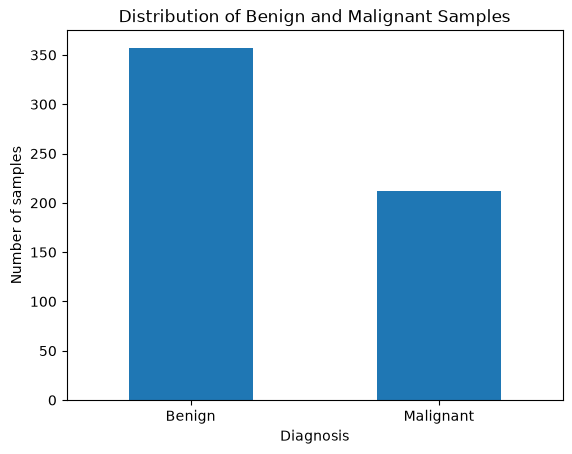

In [8]:
import matplotlib.pyplot as plt

df["diagnosis"].value_counts().plot(kind="bar")

plt.xlabel("Diagnosis")
plt.ylabel("Number of samples")
plt.title("Distribution of Benign and Malignant Samples")
plt.xticks([0, 1], ["Benign", "Malignant"], rotation=0)

plt.show()

In [9]:
print(X.corr()["radius_mean"].sort_values(ascending=False))

radius_mean                1.000000
perimeter_mean             0.997855
area_mean                  0.987357
radius_worst               0.969539
perimeter_worst            0.965137
area_worst                 0.941082
concave points_mean        0.822529
concave points_worst       0.744214
area_se                    0.735864
radius_se                  0.679090
concavity_mean             0.676764
perimeter_se               0.674172
concavity_worst            0.526911
compactness_mean           0.506124
compactness_worst          0.413463
concave points_se          0.376169
texture_mean               0.323782
texture_worst              0.297008
compactness_se             0.206000
concavity_se               0.194204
smoothness_mean            0.170581
symmetry_worst             0.163953
symmetry_mean              0.147741
smoothness_worst           0.119616
fractal_dimension_worst    0.007066
fractal_dimension_se      -0.042641
texture_se                -0.097317
symmetry_se               -0

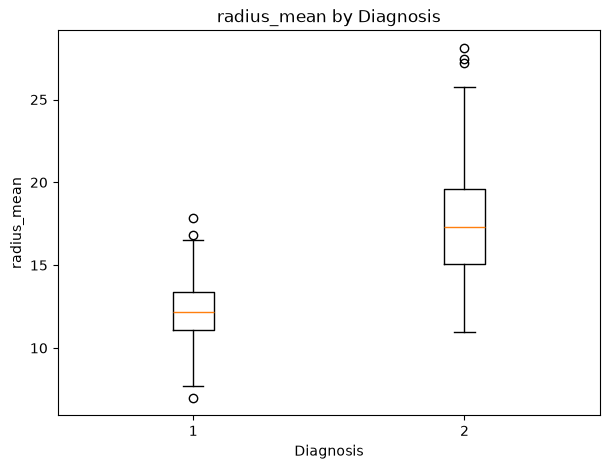

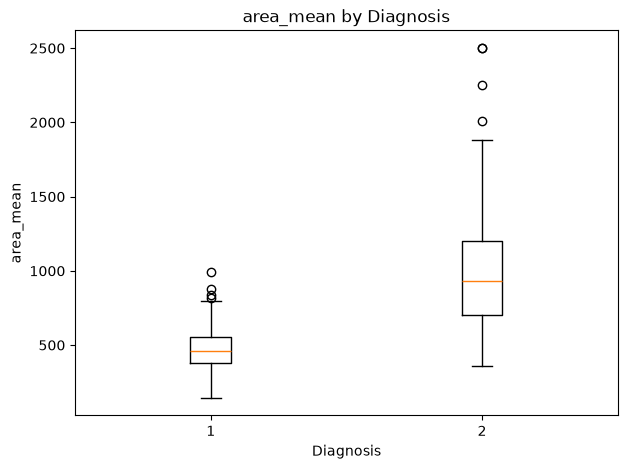

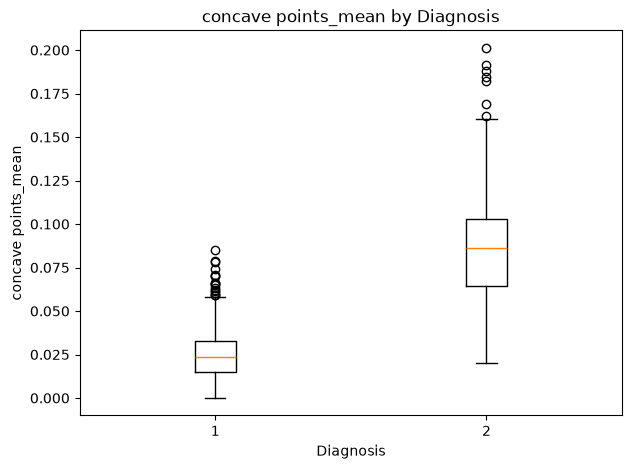

In [10]:
features_to_plot = [
    "radius_mean",
    "area_mean",
    "concave points_mean"
]

for feature in features_to_plot:

    plt.figure(figsize=(7, 5))

    plt.boxplot(
        [
            df[df["diagnosis"] == 0][feature],
            df[df["diagnosis"] == 1][feature]
        ],
        label=["Benign", "Malignant"]
    )

    plt.xlabel("Diagnosis")
    plt.ylabel(feature)
    plt.title(f"{feature} by Diagnosis")

    plt.show()

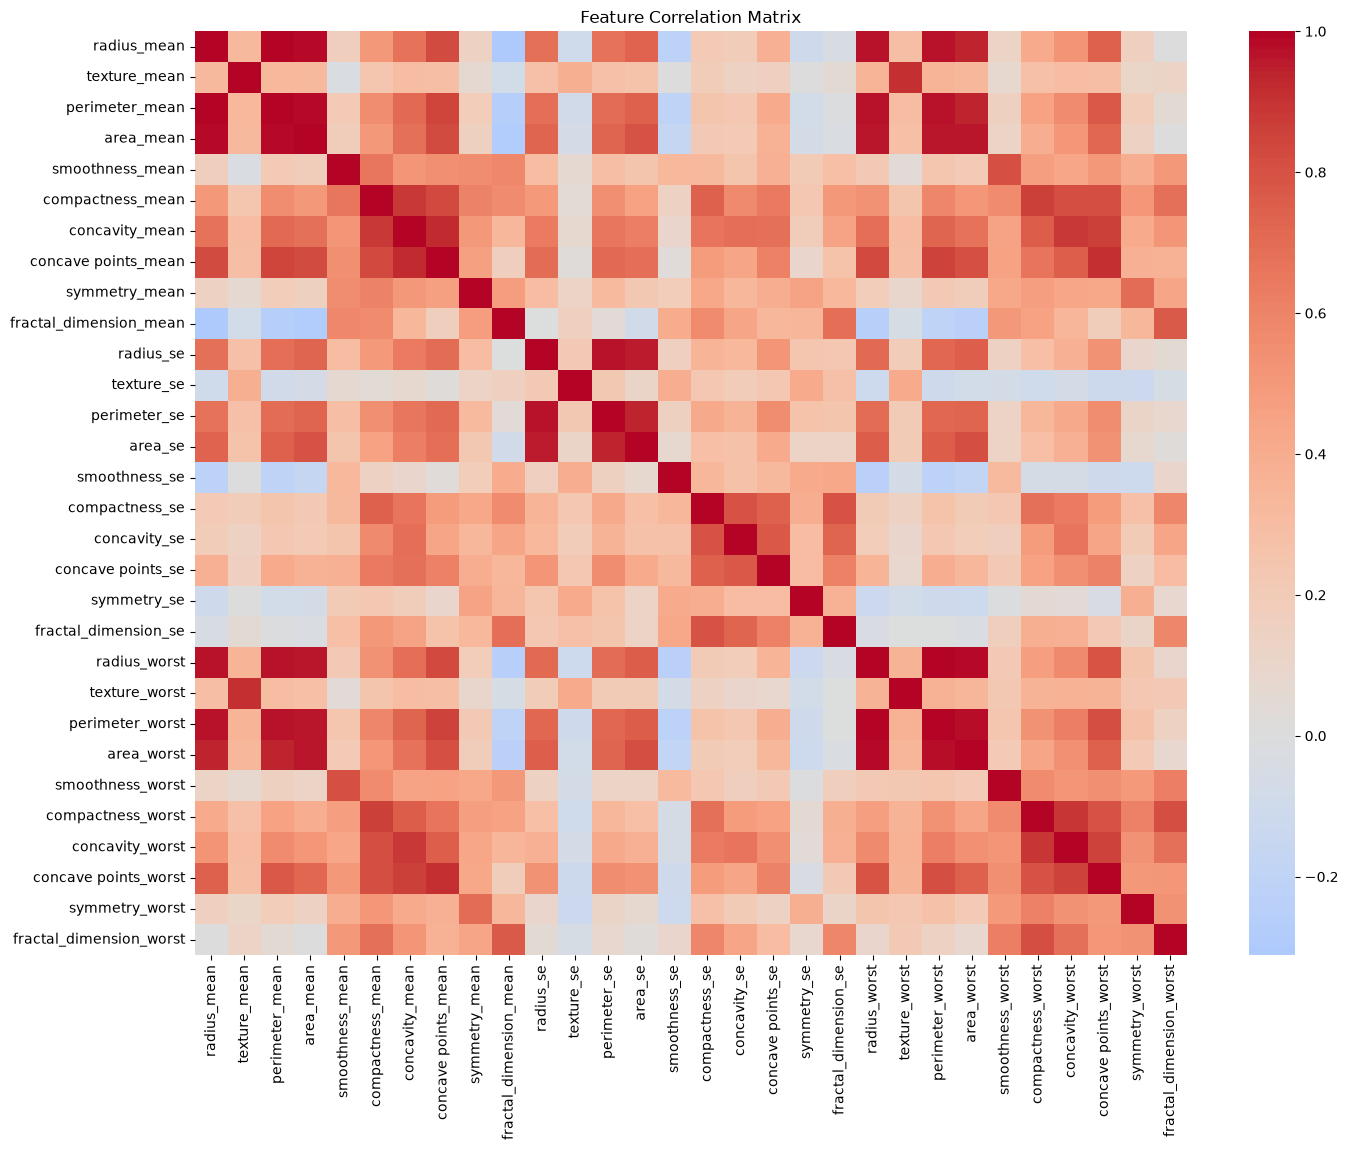

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 12))

sns.heatmap(
    X.corr(),
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Matrix")
plt.show()

In [12]:
print(X[[
    "radius_mean",
    "area_mean",
    "smoothness_mean"
]].describe().loc[["min", "max"]])

     radius_mean  area_mean  smoothness_mean
min        6.981      143.5          0.05263
max       28.110     2501.0          0.16340


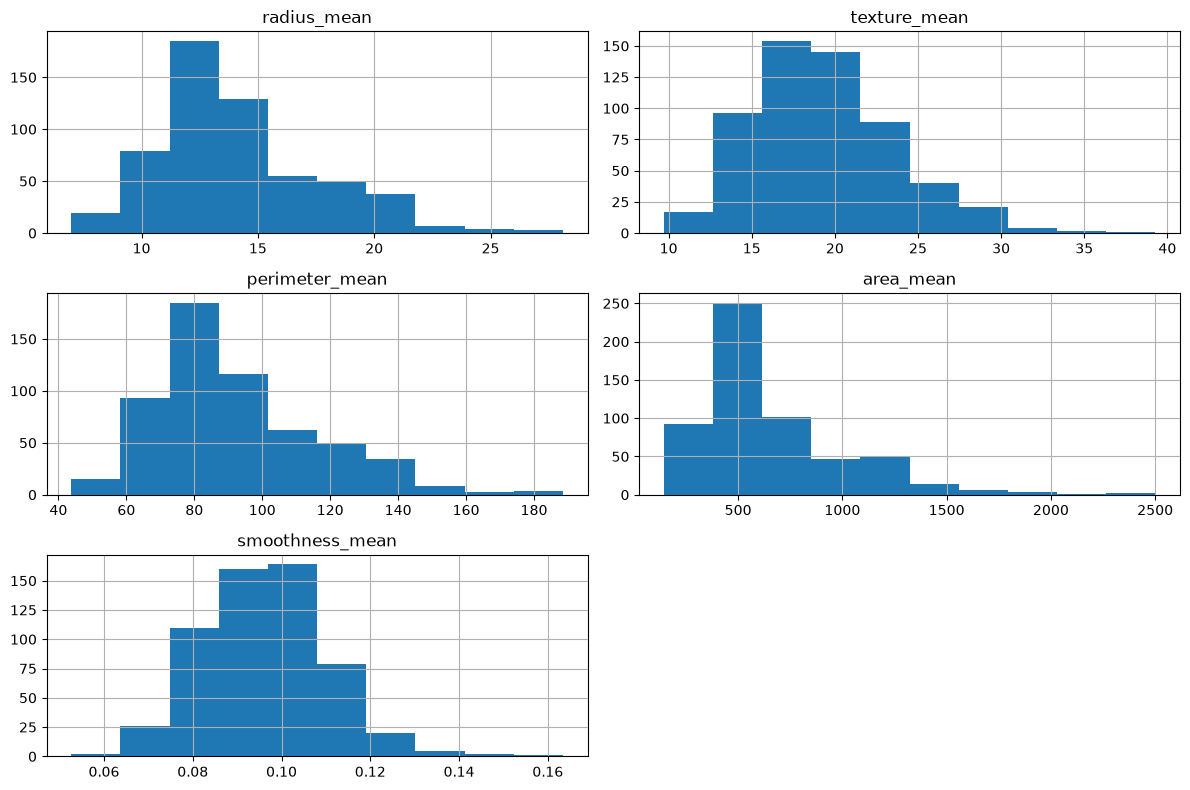

In [13]:
X[
    [
        "radius_mean",
        "texture_mean",
        "perimeter_mean",
        "area_mean",
        "smoothness_mean"
    ]
].hist(figsize=(12, 8))

plt.tight_layout()
plt.show()

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [15]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (455, 30)
X_test : (114, 30)
y_train: (455,)
y_test : (114,)


In [16]:
print("Training distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())

Training distribution:
diagnosis
0    285
1    170
Name: count, dtype: int64

Testing distribution:
diagnosis
0    72
1    42
Name: count, dtype: int64


In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [18]:
import pandas as pd

scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns
)

print(scaled_df[[
    "radius_mean",
    "area_mean",
    "smoothness_mean"
]].describe().loc[["mean", "std"]])

       radius_mean     area_mean  smoothness_mean
mean -1.737316e-16 -1.171224e-16     7.242070e-16
std   1.001101e+00  1.001101e+00     1.001101e+00


In [19]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [20]:
y_pred = model.predict(X_test_scaled)
print("Predictions:", y_pred)

Predictions: [0 1 0 1 1 0 1 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 1 1 1 0 0 1 1 1 1 0 1 1 0 0 0
 0 1 0 0 0 1 0 0 1 0 1 0 0 1 1 0 0 0 1 0 0 0 1 0 0 1 0 0 0 1 1 0 1 0 1 1 0
 0 0 0 1 0 1 1 1 0 0 0 0 1 0 1 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 1 0 0
 0 0 1]


In [21]:
y_prob = model.predict_proba(X_test_scaled)

print(y_prob[:5])

[[9.99635432e-01 3.64568116e-04]
 [1.07465986e-08 9.99999989e-01]
 [9.57432053e-01 4.25679471e-02]
 [4.23812678e-01 5.76187322e-01]
 [4.90844511e-01 5.09155489e-01]]


In [22]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.9649122807017544


In [23]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.96      0.99      0.97        72
           1       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



In [24]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[71  1]
 [ 3 39]]


In [25]:
coefficients = pd.DataFrame({
    "feature": X_train.columns,
    "coefficient": model.coef_[0]
})

coefficients["absolute_coefficient"] = coefficients["coefficient"].abs()

coefficients = coefficients.sort_values(
    "absolute_coefficient",
    ascending=False
)

print(coefficients)

                    feature  coefficient  absolute_coefficient
21            texture_worst     1.434093              1.434093
10                radius_se     1.233325              1.233325
28           symmetry_worst     1.061264              1.061264
7       concave points_mean     0.952813              0.952813
26          concavity_worst     0.911406              0.911406
13                  area_se     0.909029              0.909029
15           compactness_se    -0.906925              0.906925
23               area_worst     0.900477              0.900477
20             radius_worst     0.896968              0.896968
6            concavity_mean     0.782298              0.782298
12             perimeter_se     0.748295              0.748295
22          perimeter_worst     0.723111              0.723111
27     concave points_worst     0.703999              0.703999
19     fractal_dimension_se    -0.593876              0.593876
1              texture_mean     0.482219              0

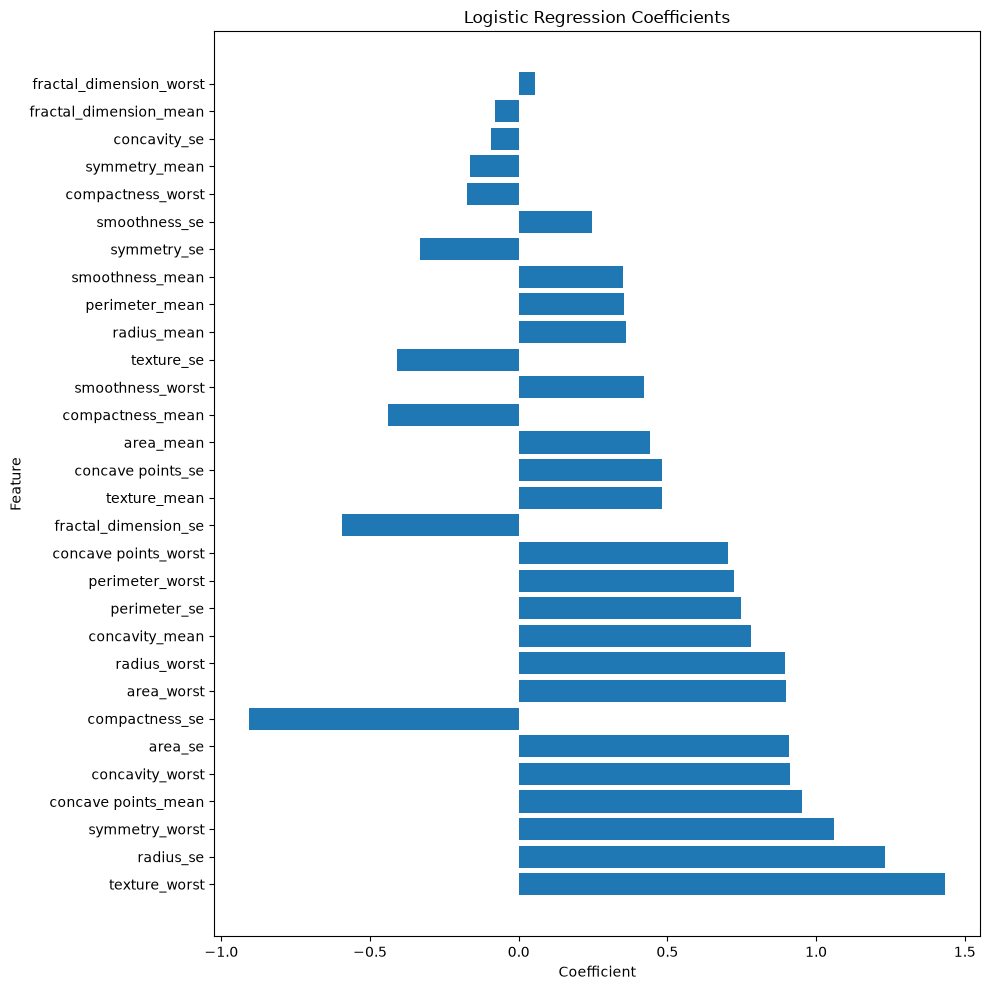

In [26]:
plt.figure(figsize=(10, 10))

plt.barh(
    coefficients["feature"],
    coefficients["coefficient"]
)

plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.title("Logistic Regression Coefficients")

plt.tight_layout()
plt.show()

In [27]:
from sklearn.metrics import roc_curve, roc_auc_score

y_prob = model.predict_proba(X_test_scaled)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC:", auc)

ROC-AUC: 0.996031746031746


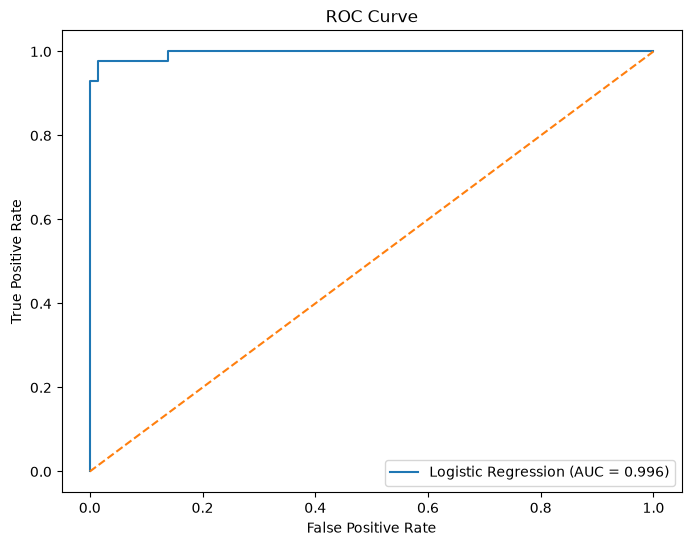

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()

plt.show()

In [29]:
from sklearn.tree import DecisionTreeClassifier

clf = DecisionTreeClassifier(random_state=42)

clf.fit(X_train_scaled, y_train)

clf_pred = clf.predict(X_test_scaled)

In [31]:
accuracy = accuracy_score(y_test, clf_pred)
print("Decision Tree Accuracy:", accuracy)

Decision Tree Accuracy: 0.9298245614035088


In [32]:
clf_report = classification_report(y_test, clf_pred)
print(clf_report)

              precision    recall  f1-score   support

           0       0.94      0.94      0.94        72
           1       0.90      0.90      0.90        42

    accuracy                           0.93       114
   macro avg       0.92      0.92      0.92       114
weighted avg       0.93      0.93      0.93       114



In [33]:
cm = confusion_matrix(y_test, clf_pred)
print(cm)

[[68  4]
 [ 4 38]]


In [36]:
from sklearn.ensemble import RandomForestClassifier

rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)
rf_clf.fit(X_train_scaled, y_train)
rf_pred = rf_clf.predict(X_test_scaled)
rf_accuracy = accuracy_score(y_test, rf_pred)
print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.9736842105263158


In [37]:
clf_report = classification_report(y_test, rf_pred)
print(clf_report)


              precision    recall  f1-score   support

           0       0.96      1.00      0.98        72
           1       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



In [39]:
cm = confusion_matrix(y_test, rf_pred)
print(cm)

[[72  0]
 [ 3 39]]


In [40]:

from sklearn.model_selection import cross_val_score


cross_val_scores = cross_val_score(
    rf_clf,
    X_train_scaled,
    y_train,
    cv=5
)
print("Cross-Validation Scores:", cross_val_scores)
print("Mean CV Score:", cross_val_scores.mean())

Cross-Validation Scores: [1.         0.98901099 0.93406593 0.97802198 0.91208791]
Mean CV Score: 0.9626373626373628
